In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 

In [3]:
#Завантажено з www.kaggle.com/datasets/arjunbhasin2013/ccdata
ccdata = pd.read_csv('CC GENERAL.csv')
ccdata.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [16]:
ccdata['BALANCE'].max()

np.float64(19043.13856)

In [4]:
ccdata.tail()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.50,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.00,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.25,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.25,6
8949,C19190,372.708075,0.666667,1093.25,1093.25,0.00,127.040008,0.666667,0.666667,0.000000,0.333333,2,23,1200.0,63.165404,88.288956,0.00,6


In [ ]:
# Подивимося на кількість нульових значеннь
ccdata.isnull().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

NaN має сенс для мінімального платежу (якщо не було жодного). Кредитний ліміт для одного учасника не виставлений, треба його почистити

In [9]:
ccdata = ccdata.dropna(subset=['CREDIT_LIMIT'])

In [11]:
# Будуємо DataFrame стовпців, які використовуватимемо, як ознаки 
x = ccdata[['BALANCE', 'CREDIT_LIMIT']].values

### Етап побудови моделі

Реалізація алгоритму k-середніх для визначення оптимальної кількості кластерів. Завантажуємо Kmeans

In [10]:
from sklearn.cluster import KMeans
clalist=[]

Будемо використовувати метод Elbow для визначення k з параметром "k-means++"

In [12]:
#inertia_ - це метод, який розділяє точки даних на кластери
for i in range(1,11):
    kmeans = KMeans(n_clusters= i, init='k-means++', random_state=17)
    kmeans.fit(x)
    clalist.append(kmeans.inertia_)    

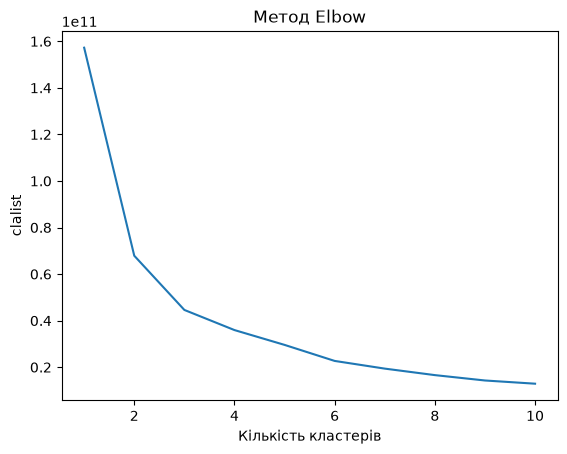

In [13]:
plt.plot(range(1,11), clalist)
plt.title('Метод Elbow')
plt.xlabel('Кількість кластерів')
plt.ylabel('clalist')
plt.show()

In [14]:
kmeansmodel = KMeans(n_clusters= 3, init='k-means++', random_state=17)
y_kmeans= kmeansmodel.fit_predict(x)
print(kmeansmodel.cluster_centers_)

[[ 5291.05718336 12639.52784504]
 [  792.47191074  2168.49407421]
 [ 1986.18220329  6714.79480908]]


### Етап візуалізації

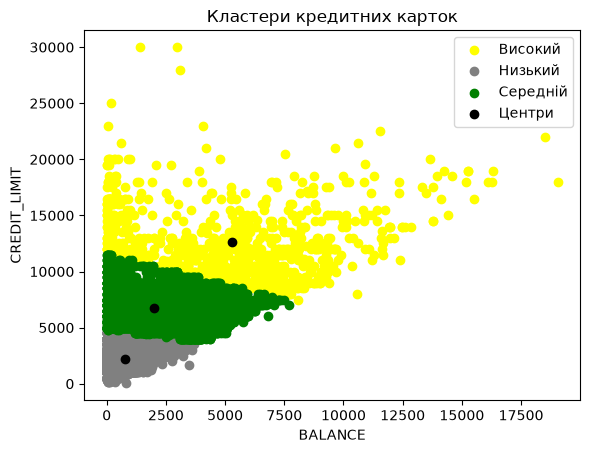

In [19]:
plt.scatter(x[y_kmeans == 0, 0], x[y_kmeans == 0, 1], c = 'yellow', label = 'Високий')
plt.scatter(x[y_kmeans == 1, 0], x[y_kmeans == 1, 1], c = 'gray', label = 'Низький')
plt.scatter(x[y_kmeans == 2, 0], x[y_kmeans == 2, 1], c = 'green', label = 'Середній')
plt.scatter(kmeansmodel.cluster_centers_[:, 0], kmeansmodel.cluster_centers_[:, 1], c = 'black', label = 'Центри')
plt.title('Кластери кредитних карток')
plt.xlabel('BALANCE')
plt.ylabel('CREDIT_LIMIT')
plt.legend()
plt.show()